In [38]:
import uproot
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp, chi2 as chi2_dist

import sys
sys.path.insert(0, '/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/')
import os; os.environ['MEDULLA_PLOT_DIR'] = '/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/'

import matplotlib.pyplot as plt
from style import stamp

plt.style.use('/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/styles/nue2024.mplstyle')

from scipy.optimize import curve_fit


In [91]:
fin_e = uproot.open("/exp/icarus/data/users/micarrig/merged_nue_v31.root")
fin = uproot.open("/exp/icarus/data/users/micarrig/merged_final_v31e_flux.root")

In [92]:
def double_crystal_ball(x, N, mu, sigma, aL, nL, aR, nR):
    """Double-sided Crystal Ball: Gaussian core with power-law tails on both sides."""
    t = (x - mu) / sigma
    y = np.exp(-0.5 * t**2)
    with np.errstate(over='ignore', divide='ignore', invalid='ignore'):
        lo = t < -aL
        AL = (nL / aL)**nL * np.exp(-0.5 * aL**2)
        BL = nL / aL - aL
        y = np.where(lo, AL * (BL - t)**(-nL), y)
        hi = t > aR
        AR = (nR / aR)**nR * np.exp(-0.5 * aR**2)
        BR = nR / aR - aR
        y = np.where(hi, AR * (BR + t)**(-nR), y)
    return N * y

def fit_text(label, popt, perr):
    N, mu, sig, aL, nL, aR, nR = popt
    Ne, mue, sige, aLe, nLe, aRe, nRe = perr
    return (
        f'{label} fit\n'
        f'$\\mu = {mu:.1f} \\pm {mue:.1f}$ MeV\n'
        f'$\\sigma = {sig:.1f} \\pm {sige:.1f}$ MeV\n'
        f'$\\alpha_L = {aL:.2f} \\pm {aLe:.2f}$,  $n_L = {nL:.1f} \\pm {nLe:.1f}$\n'
        f'$\\alpha_R = {aR:.2f} \\pm {aRe:.2f}$,  $n_R = {nR:.1f} \\pm {nRe:.1f}$'
    )

def fit_and_plot(data, color, label, bins=100, range=(0, 300)):
    counts_norm, edges = np.histogram(data, bins=bins, range=range, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    ax.hist(data, bins=bins, range=range, histtype='step', density=True, label=label, color=color)
    p0 = [counts_norm.max(), 135.0, 25.0, 1.5, 3.0, 1.5, 3.0]
    mask = counts_norm > 0
    popt, pcov = curve_fit(double_crystal_ball, centers[mask], counts_norm[mask], p0=p0, bounds=bounds, maxfev=10000)
    perr = np.sqrt(np.diag(pcov))
    ax.plot(x_fit, double_crystal_ball(x_fit, *popt), color=color, linestyle='--', lw=2, label=f'{label} fit')
    return popt, perr

# Compare pi0 mass in cv/var

## nue enhanced

In [93]:
r_pi0 = fin_e['events/NuMI_nue/nc_sideband'].arrays(["reco_pi0_invariant_mass"], library="np")
t_pi0 = fin_e['events/NuMI_nue/nc_sideband'].arrays(["true_pi0_invariant_mass"], library="np")

r_var_pi0 = fin_e['events/recombination/nc_sideband'].arrays(["reco_pi0_invariant_mass"], library="np")

r_data_pi0 = fin['events/data/nc_sideband'].arrays(["reco_pi0_invariant_mass"], library="np")

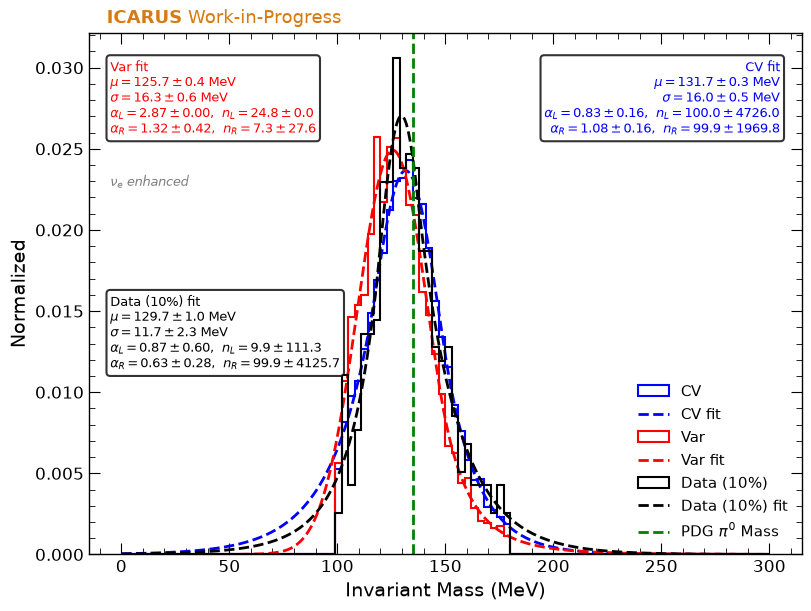

In [121]:

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

bounds = ([0, 80, 5, 0.1, 1.01, 0.1, 1.01], [np.inf, 180, 80, 10, 100, 10, 100])
x_fit = np.linspace(0, 300, 1000)

popt_cv,   perr_cv   = fit_and_plot(r_pi0['reco_pi0_invariant_mass'],      'blue',   'CV')
popt_var,  perr_var  = fit_and_plot(r_var_pi0['reco_pi0_invariant_mass'],  'red',    'Var')
popt_data, perr_data = fit_and_plot(r_data_pi0['reco_pi0_invariant_mass'], 'black', 'Data (10%)')

ax.text(0.97, 0.95, fit_text('CV',   popt_cv,   perr_cv),   transform=ax.transAxes, fontsize=9,
        va='top', ha='right', color='blue',   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(0.03, 0.95, fit_text('Var',  popt_var,  perr_var),  transform=ax.transAxes, fontsize=9,
        va='top', ha='left',  color='red',    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(0.03, 0.50, fit_text('Data (10%)', popt_data, perr_data), transform=ax.transAxes, fontsize=9,
        va='top', ha='left',  color='black', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.axvline(134.98, color='green', linestyle='--', label='PDG $\\pi^0$ Mass')

ax.set_xlabel('Invariant Mass (MeV)')
ax.set_ylabel('Normalized')
ax.legend()

stamp(ax, pot=None, work_in_progress=True)

ax.text(0.03, 0.7, r'$\nu_e$ enhanced', transform=ax.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.show()


## Standard Var

In [95]:
r_pi0 = fin['events/NuMIFull/nc_sideband'].arrays(["reco_pi0_invariant_mass"], library="np")
t_pi0 = fin['events/NuMIFull/nc_sideband'].arrays(["true_pi0_invariant_mass"], library="np")

r_var_pi0 = fin['events/recombination/nc_sideband'].arrays(["reco_pi0_invariant_mass"], library="np")

r_data_pi0 = fin['events/data/nc_sideband'].arrays(["reco_pi0_invariant_mass"], library="np")

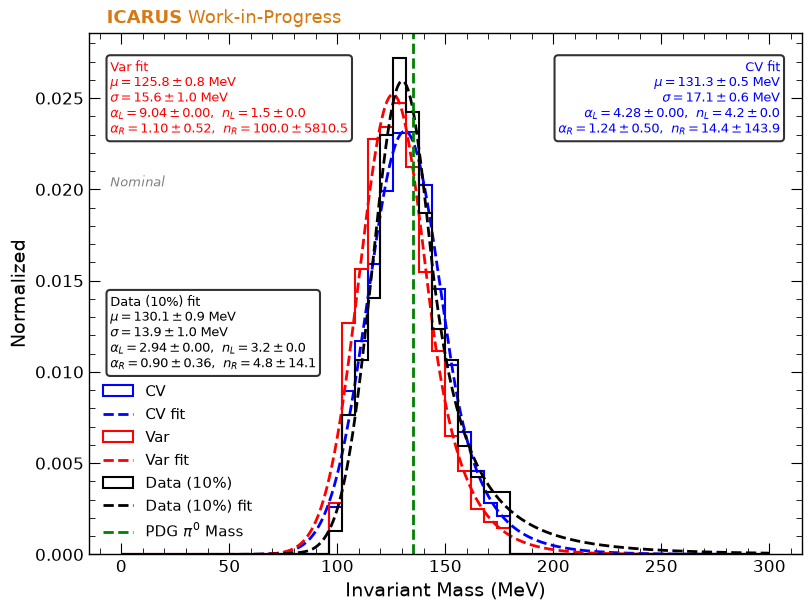

In [120]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

bounds = ([0, 80, 5, 0.1, 1.01, 0.1, 1.01], [np.inf, 180, 80, 10, 100, 10, 100])
x_fit = np.linspace(0, 300, 1000)

popt_cv,   perr_cv   = fit_and_plot(r_pi0['reco_pi0_invariant_mass'],      'blue',   'CV', bins=50)
popt_var,  perr_var  = fit_and_plot(r_var_pi0['reco_pi0_invariant_mass'],  'red',    'Var', bins=50)
popt_data, perr_data = fit_and_plot(r_data_pi0['reco_pi0_invariant_mass'], 'black', 'Data (10%)', bins=50)

ax.text(0.97, 0.95, fit_text('CV',   popt_cv,   perr_cv),   transform=ax.transAxes, fontsize=9,
        va='top', ha='right', color='blue',   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(0.03, 0.95, fit_text('Var',  popt_var,  perr_var),  transform=ax.transAxes, fontsize=9,
        va='top', ha='left',  color='red',    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(0.03, 0.50, fit_text('Data (10%)', popt_data, perr_data), transform=ax.transAxes, fontsize=9,
        va='top', ha='left',  color='black', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.axvline(134.98, color='green', linestyle='--', label='PDG $\\pi^0$ Mass')

ax.set_xlabel('Invariant Mass (MeV)')
ax.set_ylabel('Normalized')
ax.legend()

stamp(ax, pot=None, work_in_progress=True)

ax.text(0.03, 0.7, r'Nominal', transform=ax.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.show()


## Gaussian fit (100–180 MeV window)

The selection requires 100 < m(π⁰) < 180 MeV, so Crystal Ball tails outside
that range are absent and the tail parameters are unconstrained. A Gaussian
fit restricted to the selection window gives stable μ and σ.

In [97]:
def gaussian(x, N, mu, sig):
    return N * np.exp(-0.5 * ((x - mu) / sig) ** 2)

def fit_gauss_text(label, popt, perr):
    N, mu, sig = popt
    Ne, mue, sige = perr
    return f'{label} (Gauss)\n$\\mu = {mu:.1f} \\pm {mue:.1f}$ MeV\n$\\sigma = {sig:.1f} \\pm {sige:.1f}$ MeV'

def fit_and_plot_gauss(data, color, label, fit_range=(100, 180), bins=50, hist_range=(0, 300)):
    counts, edges = np.histogram(data, bins=bins, range=hist_range, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    ax.hist(data, bins=bins, range=hist_range, histtype='step', density=True, label=label, color=color)
    mask = (centers >= fit_range[0]) & (centers <= fit_range[1]) & (counts > 0)
    p0 = [counts[mask].max(), 130.0, 15.0]
    popt, pcov = curve_fit(gaussian, centers[mask], counts[mask], p0=p0)
    perr = np.sqrt(np.diag(pcov))
    x_gauss = np.linspace(*fit_range, 500)
    ax.plot(x_gauss, gaussian(x_gauss, *popt), color=color, linestyle='--', lw=2,
            label=f'{label} Gauss fit')
    return popt, perr


### nue enhanced

In [98]:
r_pi0_e     = fin_e['events/NuMI_nue/nc_sideband'].arrays(['reco_pi0_invariant_mass'], library='np')
r_var_pi0_e = fin_e['events/recombination/nc_sideband'].arrays(['reco_pi0_invariant_mass'], library='np')


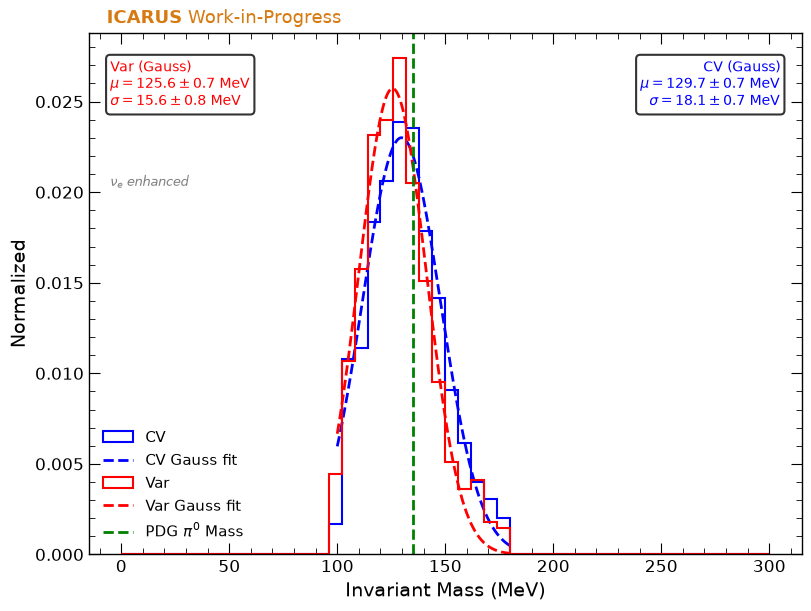

CV peak:  129.70 +/- 0.68 MeV
Var peak: 125.62 +/- 0.68 MeV
CV - Var: 4.08 +/- 0.96 MeV  (3.15%)


In [122]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

popt_cv_g,  perr_cv_g  = fit_and_plot_gauss(r_pi0_e['reco_pi0_invariant_mass'],   'blue',  'CV')
popt_var_g, perr_var_g = fit_and_plot_gauss(r_var_pi0_e['reco_pi0_invariant_mass'],'red',   'Var')

ax.text(0.97, 0.95, fit_gauss_text('CV',  popt_cv_g,  perr_cv_g),  transform=ax.transAxes, fontsize=10,
        va='top', ha='right', color='blue',  bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(0.03, 0.95, fit_gauss_text('Var', popt_var_g, perr_var_g), transform=ax.transAxes, fontsize=10,
        va='top', ha='left',  color='red',   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.axvline(134.98, color='green', linestyle='--', label='PDG $\\pi^0$ Mass')
ax.set_xlabel('Invariant Mass (MeV)')
ax.set_ylabel('Normalized')
ax.legend()
stamp(ax, pot=None, work_in_progress=True)
ax.text(0.03, 0.7, r'$\nu_e$ enhanced', transform=ax.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.show()

gap_nue = popt_cv_g[1] - popt_var_g[1]
gap_nue_err = np.sqrt(perr_cv_g[1]**2 + perr_var_g[1]**2)
print(f'CV peak:  {popt_cv_g[1]:.2f} +/- {perr_cv_g[1]:.2f} MeV')
print(f'Var peak: {popt_var_g[1]:.2f} +/- {perr_var_g[1]:.2f} MeV')
print(f'CV - Var: {gap_nue:.2f} +/- {gap_nue_err:.2f} MeV  ({gap_nue/popt_cv_g[1]*100:.2f}%)')


### Standard

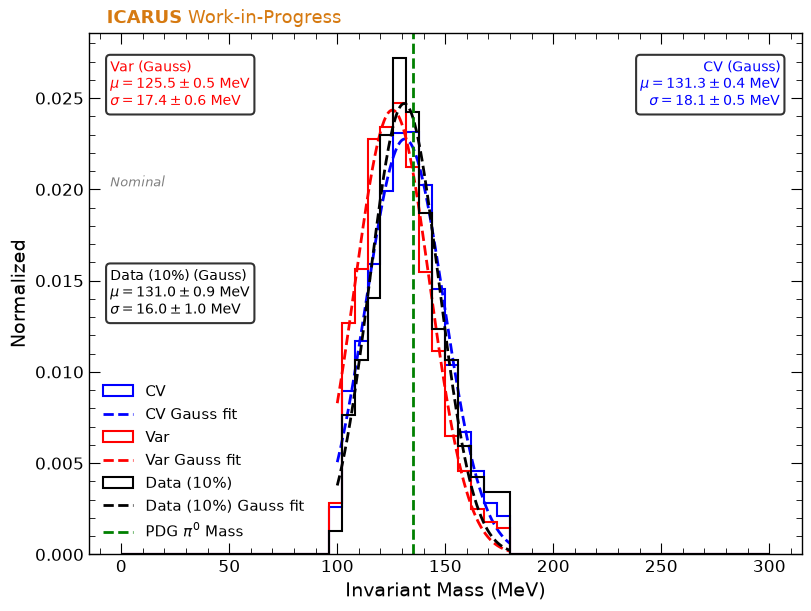

CV peak:    131.32 +/- 0.44 MeV
Var peak:   125.52 +/- 0.50 MeV
Data peak:  130.98 +/- 0.93 MeV
Data/CV gap: 0.33 +/- 1.03 MeV  (0.25 +/- 0.79%)
CV-Var shift: 4.41%
Implied sigma (gap in quadrature with error): 0.83%


In [123]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

popt_cv_g,   perr_cv_g   = fit_and_plot_gauss(r_pi0['reco_pi0_invariant_mass'],      'blue',  'CV')
popt_var_g,  perr_var_g  = fit_and_plot_gauss(r_var_pi0['reco_pi0_invariant_mass'],  'red',   'Var')
popt_data_g, perr_data_g = fit_and_plot_gauss(r_data_pi0['reco_pi0_invariant_mass'], 'black', 'Data (10%)')

ax.text(0.97, 0.95, fit_gauss_text('CV',   popt_cv_g,   perr_cv_g),   transform=ax.transAxes, fontsize=10,
        va='top', ha='right', color='blue',  bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(0.03, 0.95, fit_gauss_text('Var',  popt_var_g,  perr_var_g),  transform=ax.transAxes, fontsize=10,
        va='top', ha='left',  color='red',   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(0.03, 0.55, fit_gauss_text('Data (10%)', popt_data_g, perr_data_g), transform=ax.transAxes, fontsize=10,
        va='top', ha='left',  color='black', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.axvline(134.98, color='green', linestyle='--', label='PDG $\\pi^0$ Mass')
ax.set_xlabel('Invariant Mass (MeV)')
ax.set_ylabel('Normalized')
ax.legend()
stamp(ax, pot=None, work_in_progress=True)
ax.text(0.03, 0.7, r'Nominal', transform=ax.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.show()

gap = popt_cv_g[1] - popt_data_g[1]
gap_err = np.sqrt(perr_cv_g[1]**2 + perr_data_g[1]**2)
gap_pct = gap / popt_cv_g[1] * 100
gap_pct_err = gap_err / popt_cv_g[1] * 100
cv_var_shift = (popt_cv_g[1] - popt_var_g[1]) / popt_cv_g[1] * 100
print(f'CV peak:    {popt_cv_g[1]:.2f} +/- {perr_cv_g[1]:.2f} MeV')
print(f'Var peak:   {popt_var_g[1]:.2f} +/- {perr_var_g[1]:.2f} MeV')
print(f'Data peak:  {popt_data_g[1]:.2f} +/- {perr_data_g[1]:.2f} MeV')
print(f'Data/CV gap: {gap:.2f} +/- {gap_err:.2f} MeV  ({gap_pct:.2f} +/- {gap_pct_err:.2f}%)')
print(f'CV-Var shift: {cv_var_shift:.2f}%')
sigma = np.sqrt(gap_pct**2 + gap_pct_err**2)
print(f'Implied sigma (gap in quadrature with error): {sigma:.2f}%')


## Fit-range systematic

Vary the fit window to estimate how much the peak positions depend on the
range choice. The spread in μ_CV and μ_data across windows is an additional
uncertainty on the gap.

In [101]:
def gauss_peak(data, fit_range, bins=50, hist_range=(0, 300)):
    """Return (mu, mu_err) from a Gaussian fit within fit_range."""
    counts, edges = np.histogram(data, bins=bins, range=hist_range, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    mask = (centers >= fit_range[0]) & (centers <= fit_range[1]) & (counts > 0)
    p0 = [counts[mask].max(), 130.0, 15.0]
    popt, pcov = curve_fit(gaussian, centers[mask], counts[mask], p0=p0)
    return popt[1], np.sqrt(pcov[1, 1])

cv_data   = r_pi0['reco_pi0_invariant_mass']
var_data  = r_var_pi0['reco_pi0_invariant_mass']
dat_data  = r_data_pi0['reco_pi0_invariant_mass']

windows = [(90, 180), (95, 180), (100, 180), (105, 180), (110, 180),
           (100, 170), (100, 175), (100, 185)]

print(f'{'Window':>14}  {'μ_CV':>10}  {'μ_Data':>10}  {'gap (MeV)':>10}  {'gap (%)':>8}  {'σ_gap (%)':>10}')
print('-' * 80)

gaps_pct = []
for lo, hi in windows:
    try:
        mu_cv,  e_cv  = gauss_peak(cv_data,  (lo, hi))
        mu_dat, e_dat = gauss_peak(dat_data, (lo, hi))
        gap_mev = mu_cv - mu_dat
        gap_pct = gap_mev / mu_cv * 100
        sgap    = np.sqrt(e_cv**2 + e_dat**2) / mu_cv * 100
        gaps_pct.append(gap_pct)
        print(f'[{lo:3d}, {hi:3d}] MeV  {mu_cv:10.2f}  {mu_dat:10.2f}  {gap_mev:10.3f}  {gap_pct:8.3f}  {sgap:10.3f}')
    except Exception as exc:
        print(f'[{lo:3d}, {hi:3d}] MeV  FAILED: {exc}')

range_sys = (max(gaps_pct) - min(gaps_pct)) / 2
print(f'\nRange systematic (half-spread): {range_sys:.3f}%')

plt.show()


        Window        μ_CV      μ_Data   gap (MeV)   gap (%)   σ_gap (%)
--------------------------------------------------------------------------------
[ 90, 180] MeV      131.54      131.11       0.430     0.327       0.764
[ 95, 180] MeV      131.54      131.11       0.430     0.327       0.764
[100, 180] MeV      131.32      130.98       0.334     0.254       0.785
[105, 180] MeV      131.32      130.98       0.334     0.254       0.785
[110, 180] MeV      131.62      131.16       0.463     0.352       0.830
[100, 170] MeV      131.26      130.88       0.377     0.287       0.710
[100, 175] MeV      131.29      130.95       0.348     0.265       0.736
[100, 185] MeV      131.32      130.98       0.334     0.254       0.785

Range systematic (half-spread): 0.049%


In [102]:
# Nominal result from the 100-180 window
gap_nom   = 0.25   # % — update from gauss_std_plot output
sgap_nom  = 0.79   # % — statistical error on gap

sigma_total = np.sqrt(gap_nom**2 + sgap_nom**2 + range_sys**2)
print(f'gap (nominal):          {gap_nom:.2f}%')
print(f'sigma_gap (stat):       {sgap_nom:.2f}%')
print(f'range systematic:       {range_sys:.3f}%')
print(f'sigma (all in quad):    {sigma_total:.3f}%')


gap (nominal):          0.25%
sigma_gap (stat):       0.79%
range systematic:       0.049%
sigma (all in quad):    0.830%


## Bin-edge sensitivity: why 300 MeV and 1.5 GeV spike

A fractional energy shift $s$ moves $s \cdot E \cdot n(E)$ events across each bin edge,
so $\Delta N / N \approx s\,(b\,n(b) - a\,n(a))\,/\,N$ for a bin $[a,b]$.
The 300 MeV bin has $n(300)\approx 0$ (threshold) but non-zero $n(390)$;
the 1.5–2 GeV bin has a falling spectrum so more events leave at 1.5 GeV than arrive at 2 GeV.

In [103]:
cv_arr  = fin_e['events/NuMI_nue/selected'].arrays(
              ['reco_leading_electron_energy', 'true_category'], library='np')
var_arr = fin_e['events/recombination/selected'].arrays(
              ['reco_leading_electron_energy', 'true_category'], library='np')

sig_cv  = cv_arr['true_category'] == 0
sig_var = var_arr['true_category'] == 0
cv_E  = cv_arr['reco_leading_electron_energy'][sig_cv]
var_E = var_arr['reco_leading_electron_energy'][sig_var]
print(f'CV signal: {sig_cv.sum()}  Var signal: {sig_var.sum()}')

# GUNDAM spline bin edges (MeV)
edges = np.array([300, 390, 490, 600, 730, 870, 1030, 1240, 1500, 2000, 5000])
s_shift = 0.044  # 4.4% downward scale (CV -> Var)

# Fine-bin spectrum: events/MeV
dE = 40
fine_edges   = np.arange(200, 5101, dE)
fine_centers = 0.5 * (fine_edges[:-1] + fine_edges[1:])
cv_density, _ = np.histogram(cv_E, bins=fine_edges)
cv_density = cv_density.astype(float) / dE   # events/MeV

# Interpolate density at bin edges
from scipy.interpolate import interp1d
dens_fn = interp1d(fine_centers, cv_density, kind='linear',
                   bounds_error=False, fill_value=0.0)

# Per-bin predicted and actual ΔN/N (stop at 2000 MeV for display)
disp_edges = edges  # all bins including 2000-5000 MeV
n_bins = len(disp_edges) - 1

pred   = np.zeros(n_bins)
actual = np.zeros(n_bins)
N_cv_bins = np.zeros(n_bins, dtype=int)

for i in range(n_bins):
    a, b = disp_edges[i], disp_edges[i+1]
    N_cv  = ((cv_E  >= a) & (cv_E  < b)).sum()
    N_var = ((var_E >= a) & (var_E < b)).sum()
    N_cv_bins[i] = N_cv
    if N_cv:
        pred[i]   = s_shift * (b * dens_fn(b) - a * dens_fn(a)) / N_cv * 100
        actual[i] = (N_var / N_cv - 1) * 100

# E*n(E) at display edges (the 'flux' that crosses each boundary)
edge_flux = np.array([e * float(dens_fn(e)) for e in disp_edges])

# CV spectrum scaled by 0.956 (pure scale-shift approximation)
cv_E_scaled = cv_E * 0.956
cv_density_scaled, _ = np.histogram(cv_E_scaled[cv_E_scaled >= 300], bins=fine_edges)
cv_density_scaled = cv_density_scaled.astype(float) / dE

# Signal purity per GUNDAM bin from the main NuMIFull sample
# (nue-enhanced purity is ~100% by construction; NuMIFull gives the real analysis purity)
numi_arr = fin['events/NuMIFull/selected'].arrays(
               ['reco_leading_electron_energy', 'true_category'], library='np')
E_all   = numi_arr['reco_leading_electron_energy']
cat_all = numi_arr['true_category']
purity = np.zeros(n_bins)
for i in range(n_bins):
    a, b = disp_edges[i], disp_edges[i+1]
    mask_bin = (E_all >= a) & (E_all < b)
    N_tot = mask_bin.sum()
    N_sig = (mask_bin & (cat_all == 0)).sum()
    purity[i] = N_sig / N_tot if N_tot > 0 else np.nan


CV signal: 16000  Var signal: 15221


/tmp/ipykernel_497268/3207454376.py:4: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


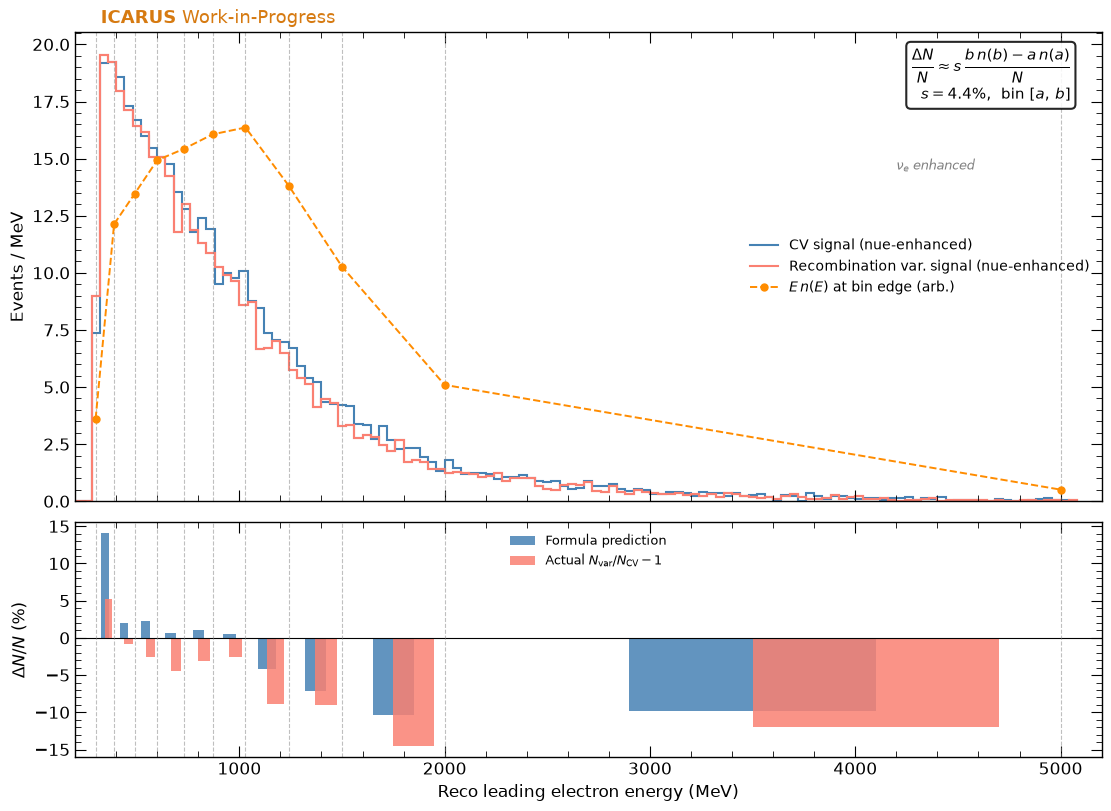

In [119]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8),
                                gridspec_kw={'height_ratios': [2, 1]},
                                sharex=True)
fig.subplots_adjust(hspace=0.05)

var_density, _ = np.histogram(var_E, bins=fine_edges)
var_density = var_density.astype(float) / dE

flux_max = edge_flux.max()

# ---- Panel 1: spectrum + E*n(E) curve ----
ax1.stairs(cv_density, fine_edges, color='steelblue', lw=1.5, label='CV signal (nue-enhanced)')

ax1.stairs(var_density, fine_edges, color='salmon', lw=1.5,
           label='Recombination var. signal (nue-enhanced)')

for edge in disp_edges:
    ax1.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)

ax1.plot(disp_edges, edge_flux / flux_max * cv_density.max() * 0.85,
         'o--', color='darkorange', ms=5, lw=1.4, label=r'$E\,n(E)$ at bin edge (arb.)')

ax1.set_xlim(200, 5200)
ax1.set_ylabel('Events / MeV', fontsize=12)
ax1.legend(fontsize=10)

stamp(ax1, pot=None, work_in_progress=True)

# Formula text box
formula = (r'$\dfrac{\Delta N}{N} \approx s\,\dfrac{b\,n(b) - a\,n(a)}{N}$'
           '\n' + r'$s = 4.4\%$,  bin $[a,\,b]$')
ax1.text(0.97, 0.97, formula, transform=ax1.transAxes, fontsize=11,
         va='top', ha='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

# ---- Panel 2: predicted vs actual ΔN/N, bars placed at bin centres in MeV ----
bin_lo  = disp_edges[:-1].astype(float)
bin_hi  = disp_edges[1:].astype(float)
centers = 0.5 * (bin_lo + bin_hi)
widths  = (bin_hi - bin_lo) * 0.4   # 40% of bin width per bar

ax2.bar(centers - widths*0.5, pred,   widths, label='Formula prediction',
        color='steelblue', alpha=0.85, align='edge')
ax2.bar(centers + widths*0.0, actual, widths, label=r'Actual $N_\mathrm{var}/N_\mathrm{CV}-1$',
        color='salmon',    alpha=0.85, align='edge')
ax2.axhline(0, color='black', lw=0.8)

ax1.stairs(var_density, fine_edges, color='salmon', lw=1.5,
           label='Recombination var. signal (nue-enhanced)')

for edge in disp_edges:
    ax2.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)

ax2.set_ylabel(r'$\Delta N/N$ (%)', fontsize=12)
ax2.set_xlabel('Reco leading electron energy (MeV)', fontsize=12)
ax2.legend(fontsize=9)

ax1.text(0.80, 0.70, r'$\nu_e$ enhanced', transform=ax1.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.savefig('bin_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()


## Simplified: spectrum shift + per-bin ratio

/tmp/ipykernel_497268/1095264952.py:4: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


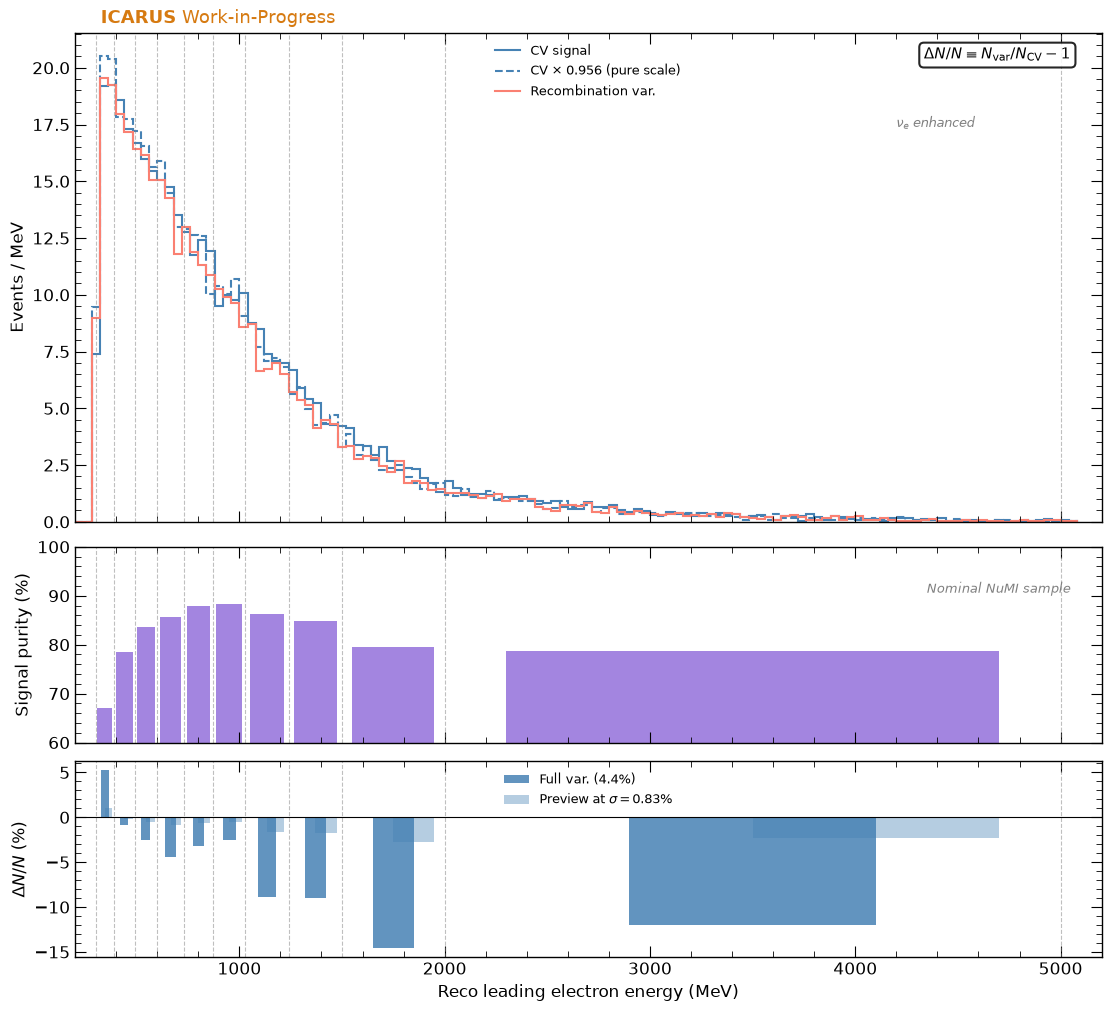

In [117]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 10),
                                      gridspec_kw={'height_ratios': [2.5, 1, 1]},
                                      sharex=True)
fig.subplots_adjust(hspace=0.05)

# ---- Panel 1: CV, CV×0.956, and variation spectra ----
ax1.stairs(cv_density,        fine_edges, color='steelblue', lw=1.5, label='CV signal')
ax1.stairs(cv_density_scaled, fine_edges, color='steelblue', lw=1.5, ls='--',
           label=r'CV $\times$ 0.956 (pure scale)')
ax1.stairs(var_density,       fine_edges, color='salmon',    lw=1.5, label='Recombination var.')

for edge in disp_edges:
    ax1.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)

ax1.set_xlim(200, 5200)
ax1.set_ylabel('Events / MeV', fontsize=12)
ax1.legend(fontsize=9)
ax1.text(0.97, 0.97,
         r'$\Delta N/N \equiv N_\mathrm{var}/N_\mathrm{CV} - 1$',
         transform=ax1.transAxes, fontsize=11, va='top', ha='right',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
stamp(ax1, pot=None, work_in_progress=True)

# ---- Panel 2: signal purity per bin ----
bin_lo  = disp_edges[:-1].astype(float)
bin_hi  = disp_edges[1:].astype(float)
centers = 0.5 * (bin_lo + bin_hi)
widths  = (bin_hi - bin_lo) * 0.8

ax2.bar(centers, purity * 100, widths, color='mediumpurple', alpha=0.85)
ax2.axhline(50, color='black', lw=0.8, ls='--', alpha=0.5)
for edge in disp_edges:
    ax2.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)
ax2.set_ylabel('Signal purity (%)', fontsize=12)
ax2.set_ylim(60, 100)
ax2.text(0.97, 0.75, 'Nominal NuMI sample',
         transform=ax2.transAxes, fontsize=9, va='bottom', ha='right',
         style='italic', color='gray')

# ---- Panel 3: ΔN/N full variation vs new σ=0.83% preview ----
sigma_new = 0.83
sigma_old = 4.4
w = (bin_hi - bin_lo) * 0.4

ax3.bar(centers - w * 0.5, actual,                      w, color='steelblue', alpha=0.85,
        label=f'Full var. ({sigma_old:.1f}%)', align='edge')
ax3.bar(centers + w * 0.0, actual * sigma_new / sigma_old, w, color='steelblue', alpha=0.4,
        label=f'Preview at $\\sigma={sigma_new}$%', align='edge')
ax3.axhline(0, color='black', lw=0.8)
for edge in disp_edges:
    ax3.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)
ax3.set_ylabel(r'$\Delta N/N$ (%)', fontsize=12)
ax3.set_xlabel('Reco leading electron energy (MeV)', fontsize=12)
ax3.legend(fontsize=9)

ax1.text(0.80, 0.80, r'$\nu_e$ enhanced', transform=ax1.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.savefig('bin_sensitivity_simple.png', dpi=150, bbox_inches='tight')
plt.show()


## The 4.4% shower energy scale shift

In [106]:
# Load reco and true electron energy for signal events, CV and variation
branches = ['reco_leading_electron_energy', 'true_leading_electron_energy', 'true_category']
cv_res_arr  = fin_e['events/NuMI_nue/selected'].arrays(branches, library='np')
var_res_arr = fin_e['events/recombination/selected'].arrays(branches, library='np')

sig_cv  = cv_res_arr['true_category']  == 0
sig_var = var_res_arr['true_category'] == 0

res_cv  = (cv_res_arr['reco_leading_electron_energy'][sig_cv]
           / cv_res_arr['true_leading_electron_energy'][sig_cv]) - 1
res_var = (var_res_arr['reco_leading_electron_energy'][sig_var]
           / var_res_arr['true_leading_electron_energy'][sig_var]) - 1

# Remove unphysical values
res_cv  = res_cv[(np.isfinite(res_cv))  & (np.abs(res_cv)  < 1)]
res_var = res_var[(np.isfinite(res_var)) & (np.abs(res_var) < 1)]

# Per-bin N_var/N_CV and N_scale/N_CV using cv_E, var_E, cv_E_scaled from slope_data
N_cv_bin    = np.zeros(n_bins)
N_var_bin   = np.zeros(n_bins)
N_scale_bin = np.zeros(n_bins)
for i in range(n_bins):
    a, b = disp_edges[i], disp_edges[i+1]
    N_cv_bin[i]    = ((cv_E        >= a) & (cv_E        < b)).sum()
    N_var_bin[i]   = ((var_E       >= a) & (var_E       < b)).sum()
    N_scale_bin[i] = ((cv_E_scaled >= a) & (cv_E_scaled < b)).sum()

ratio_var   = np.where(N_cv_bin > 0, N_var_bin   / N_cv_bin - 1, np.nan) * 100
ratio_scale = np.where(N_cv_bin > 0, N_scale_bin / N_cv_bin - 1, np.nan) * 100
residual    = ratio_var - ratio_scale


<>:20: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:20: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:20: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:20: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:20: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:20: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
/tmp/ipykernel_497268/285948794.py:20: SyntaxWarning: "\m" is an invalid esc

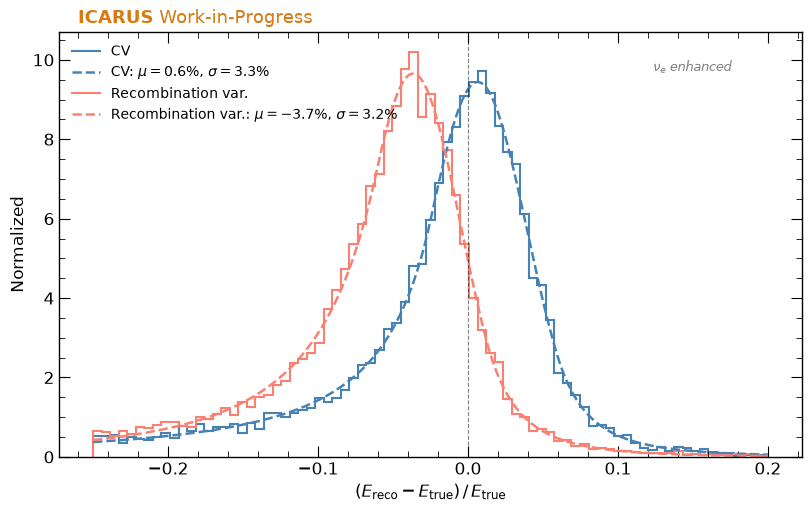

In [114]:
fig, ax = plt.subplots(figsize=(8, 5))

bins = np.linspace(-0.25, 0.20, 80)
centers = 0.5 * (bins[:-1] + bins[1:])
x_fit = np.linspace(-0.25, 0.20, 1000)

bounds_res = ([0, -0.5, 0.001, 0.1, 1.01, 0.1, 1.01],
              [np.inf, 0.5, 0.5, 10, 100, 10, 100])

for data, color, label in [(res_cv, 'steelblue', 'CV'), (res_var, 'salmon', 'Recombination var.')]:
    counts, _ = np.histogram(data, bins=bins, density=True)
    ax.stairs(counts, bins, color=color, lw=1.5, label=label)
    mask = counts > 0
    p0 = [counts[mask].max(), centers[mask][counts[mask].argmax()], 0.03, 1.5, 3.0, 1.5, 3.0]
    try:
        popt, pcov = curve_fit(double_crystal_ball, centers[mask], counts[mask],
                               p0=p0, bounds=bounds_res, maxfev=20000)
        perr = np.sqrt(np.diag(pcov))
        ax.plot(x_fit, double_crystal_ball(x_fit, *popt), color=color, ls='--', lw=1.8,
                label=f'{label}: $\mu={popt[1]*100:.1f}\%$, $\sigma={abs(popt[2])*100:.1f}\%$')
    except Exception as e:
        print(f'{label} fit failed: {e}')

ax.axvline(0, color='black', lw=0.8, ls='--', alpha=0.5)
ax.set_xlabel(r'$(E_\mathrm{reco} - E_\mathrm{true})\,/\,E_\mathrm{true}$', fontsize=12)
ax.set_ylabel('Normalized', fontsize=12)
ax.legend(fontsize=10)
stamp(ax, pot=None, work_in_progress=True)
ax.text(0.80, 0.90, r'$\nu_e$ enhanced', transform=ax.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.savefig('electron_resolution.png', dpi=150, bbox_inches='tight')
plt.show()


/tmp/ipykernel_497268/3810176781.py:4: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


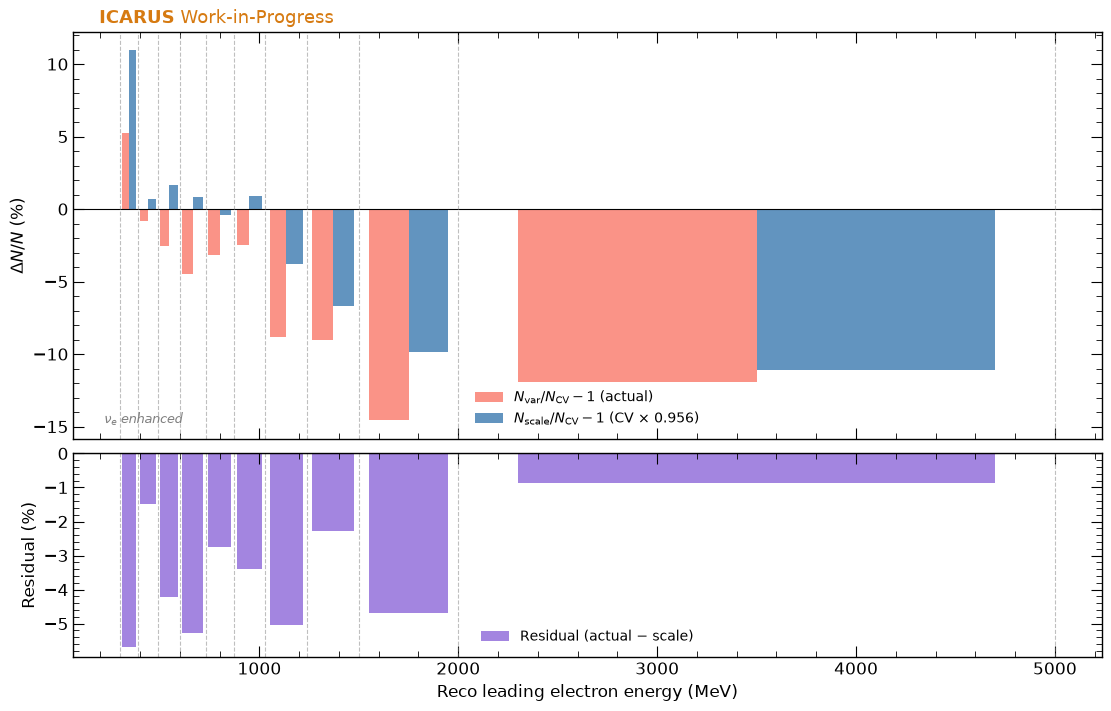

In [108]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7),
                                gridspec_kw={'height_ratios': [2, 1]},
                                sharex=True)
fig.subplots_adjust(hspace=0.05)

bin_lo_s  = disp_edges[:-1].astype(float)
bin_hi_s  = disp_edges[1:].astype(float)
centers_s = 0.5 * (bin_lo_s + bin_hi_s)
w = (bin_hi_s - bin_lo_s) * 0.4   # half-width per bar

# Side-by-side: actual on left half, scale on right half of each bin
ax1.bar(centers_s - w, ratio_var,   w, color='salmon',    alpha=0.85, align='edge',
        label=r'$N_\mathrm{var}/N_\mathrm{CV}-1$ (actual)')
ax1.bar(centers_s,     ratio_scale, w, color='steelblue', alpha=0.85, align='edge',
        label=r'$N_\mathrm{scale}/N_\mathrm{CV}-1$ (CV $\times$ 0.956)')
ax1.axhline(0, color='black', lw=0.8)
for edge in disp_edges:
    ax1.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)
ax1.set_ylabel(r'$\Delta N/N$ (%)', fontsize=12)
ax1.legend(fontsize=10)
stamp(ax1, pot=None, work_in_progress=True)

ax2.bar(centers_s, residual, (bin_hi_s - bin_lo_s) * 0.8, color='mediumpurple', alpha=0.85,
        align='center', label='Residual (actual $-$ scale)')
ax2.axhline(0, color='black', lw=0.8)
for edge in disp_edges:
    ax2.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)
ax2.set_ylabel('Residual (%)', fontsize=12)
ax2.set_xlabel('Reco leading electron energy (MeV)', fontsize=12)
ax2.legend(fontsize=10)

ax1.text(0.03, 0.03, r'$\nu_e$ enhanced', transform=ax1.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.savefig('scale_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()


## 4.4% shift — nominal NuMIFull sample

In [109]:
branches = ['reco_leading_electron_energy', 'true_leading_electron_energy', 'true_category']
cv_nom_arr  = fin['events/NuMIFull/selected'].arrays(branches, library='np')
var_nom_arr = fin['events/recombination/selected'].arrays(branches, library='np')

sig_cv_nom  = cv_nom_arr['true_category']  == 0
sig_var_nom = var_nom_arr['true_category'] == 0

res_cv_nom  = (cv_nom_arr['reco_leading_electron_energy'][sig_cv_nom]
               / cv_nom_arr['true_leading_electron_energy'][sig_cv_nom]) - 1
res_var_nom = (var_nom_arr['reco_leading_electron_energy'][sig_var_nom]
               / var_nom_arr['true_leading_electron_energy'][sig_var_nom]) - 1

res_cv_nom  = res_cv_nom[np.isfinite(res_cv_nom)   & (np.abs(res_cv_nom)  < 1)]
res_var_nom = res_var_nom[np.isfinite(res_var_nom)  & (np.abs(res_var_nom) < 1)]

cv_nom_E   = cv_nom_arr['reco_leading_electron_energy'][sig_cv_nom]
var_nom_E  = var_nom_arr['reco_leading_electron_energy'][sig_var_nom]
cv_nom_E_scaled = cv_nom_E * 0.956
cv_nom_E_scaled = cv_nom_E_scaled[cv_nom_E_scaled >= 300]

N_cv_nom    = np.zeros(n_bins)
N_var_nom   = np.zeros(n_bins)
N_scale_nom = np.zeros(n_bins)
for i in range(n_bins):
    a, b = disp_edges[i], disp_edges[i+1]
    N_cv_nom[i]    = ((cv_nom_E        >= a) & (cv_nom_E        < b)).sum()
    N_var_nom[i]   = ((var_nom_E       >= a) & (var_nom_E       < b)).sum()
    N_scale_nom[i] = ((cv_nom_E_scaled >= a) & (cv_nom_E_scaled < b)).sum()

ratio_var_nom   = np.where(N_cv_nom > 0, N_var_nom   / N_cv_nom - 1, np.nan) * 100
ratio_scale_nom = np.where(N_cv_nom > 0, N_scale_nom / N_cv_nom - 1, np.nan) * 100
residual_nom    = ratio_var_nom - ratio_scale_nom

print(f'CV signal: {sig_cv_nom.sum()}  Var signal: {sig_var_nom.sum()}')


CV signal: 9591  Var signal: 2036


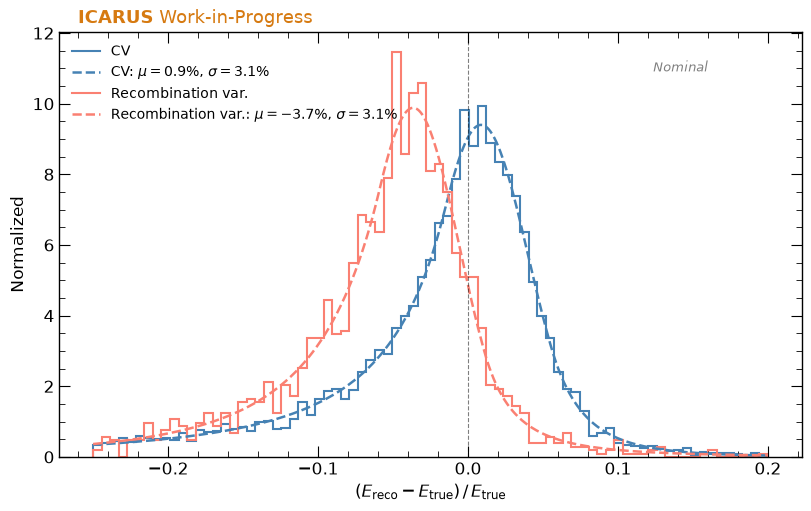

In [115]:
fig, ax = plt.subplots(figsize=(8, 5))

bins = np.linspace(-0.25, 0.20, 80)
centers_r = 0.5 * (bins[:-1] + bins[1:])
x_fit = np.linspace(-0.25, 0.20, 1000)
bounds_res = ([0, -0.5, 0.001, 0.1, 1.01, 0.1, 1.01],
              [np.inf, 0.5, 0.5, 10, 100, 10, 100])

for data, color, label in [(res_cv_nom,  'steelblue', 'CV'),
                            (res_var_nom, 'salmon',    'Recombination var.')]:
    counts, _ = np.histogram(data, bins=bins, density=True)
    ax.stairs(counts, bins, color=color, lw=1.5, label=label)
    mask = counts > 0
    p0 = [counts[mask].max(), centers_r[mask][counts[mask].argmax()], 0.03,
          1.5, 3.0, 1.5, 3.0]
    try:
        popt, pcov = curve_fit(double_crystal_ball, centers_r[mask], counts[mask],
                               p0=p0, bounds=bounds_res, maxfev=20000)
        perr = np.sqrt(np.diag(pcov))
        ax.plot(x_fit, double_crystal_ball(x_fit, *popt), color=color, ls='--', lw=1.8,
                label=f'{label}: $\\mu={popt[1]*100:.1f}\\%$, $\\sigma={abs(popt[2])*100:.1f}\\%$')
    except Exception as e:
        print(f'{label} fit failed: {e}')

ax.axvline(0, color='black', lw=0.8, ls='--', alpha=0.5)
ax.set_xlabel(r'$(E_\mathrm{reco} - E_\mathrm{true})\,/\,E_\mathrm{true}$', fontsize=12)
ax.set_ylabel('Normalized', fontsize=12)
ax.legend(fontsize=10)
stamp(ax, pot=None, work_in_progress=True)
ax.text(0.80, 0.90, r'Nominal', transform=ax.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.savefig('electron_resolution_nominal.png', dpi=150, bbox_inches='tight')
plt.show()


/tmp/ipykernel_497268/1027218568.py:4: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.05)


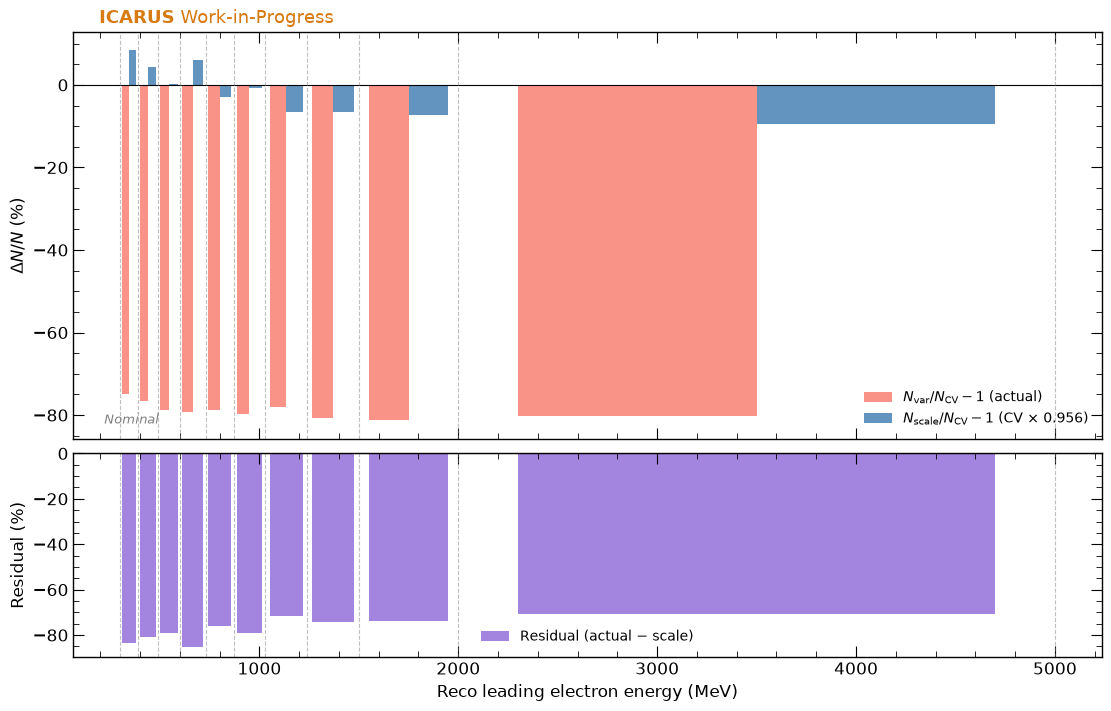

In [111]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7),
                                gridspec_kw={'height_ratios': [2, 1]},
                                sharex=True)
fig.subplots_adjust(hspace=0.05)

bin_lo_n  = disp_edges[:-1].astype(float)
bin_hi_n  = disp_edges[1:].astype(float)
centers_n = 0.5 * (bin_lo_n + bin_hi_n)
w_n = (bin_hi_n - bin_lo_n) * 0.4

ax1.bar(centers_n - w_n, ratio_var_nom,   w_n, color='salmon',    alpha=0.85, align='edge',
        label=r'$N_\mathrm{var}/N_\mathrm{CV}-1$ (actual)')
ax1.bar(centers_n,       ratio_scale_nom, w_n, color='steelblue', alpha=0.85, align='edge',
        label=r'$N_\mathrm{scale}/N_\mathrm{CV}-1$ (CV $\times$ 0.956)')
ax1.axhline(0, color='black', lw=0.8)
for edge in disp_edges:
    ax1.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)
ax1.set_ylabel(r'$\Delta N/N$ (%)', fontsize=12)
ax1.legend(fontsize=10)
stamp(ax1, pot=None, work_in_progress=True)

ax2.bar(centers_n, residual_nom, (bin_hi_n - bin_lo_n) * 0.8, color='mediumpurple',
        alpha=0.85, align='center', label='Residual (actual $-$ scale)')
ax2.axhline(0, color='black', lw=0.8)
for edge in disp_edges:
    ax2.axvline(edge, color='gray', lw=0.8, ls='--', alpha=0.5)
ax2.set_ylabel('Residual (%)', fontsize=12)
ax2.set_xlabel('Reco leading electron energy (MeV)', fontsize=12)
ax2.legend(fontsize=10)

ax1.text(0.03, 0.03, r'Nominal', transform=ax1.transAxes, fontsize=9,
         va='bottom', ha='left', style='italic', color='gray')
plt.savefig('scale_vs_actual_nominal.png', dpi=150, bbox_inches='tight')
plt.show()
